In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

In [2]:
# =============================================================================
# 0. CONFIGURATION & DATA LOADING
# =============================================================================
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)
data_dir = Path('../data')

try:
    df_tx = pd.read_csv(data_dir / "wban_sim_tx.csv")
    df_rx = pd.read_csv(data_dir / "wban_sim_lpu_rx.csv")
    df_hub = pd.read_csv(data_dir / "wban_sim_hub.csv")
    df_drops = pd.read_csv(data_dir / "wban_sim_drops.csv")
except FileNotFoundError as e:
    print(f"Error loading datasets: {e}")
    df_tx, df_rx, df_hub, df_drops = pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

# Map QoS Priorities (Updated 3-Tier Mapping)
prio_map = {0: 'CP (Priority 0)', 1: 'RP (Priority 1)', 2: 'OP (Priority 2)'}
for df in [df_tx, df_rx, df_drops, df_hub]:
    if 'Priority' in df.columns and not df.empty:
        df['QoS_Tag'] = df['Priority'].map(prio_map)

# Node Metadata Mapping (Updated with Respiration)
node_metadata = {
    2: {"SensorName": "EEG", "SensorType": "Streaming (P0)"},
    3: {"SensorName": "Respiration", "SensorType": "Streaming (P0)"}, 
    5: {"SensorName": "ECG", "SensorType": "Streaming (P0)"},
    10: {"SensorName": "EMG", "SensorType": "Streaming (P0)"},
    6: {"SensorName": "BloodPressure", "SensorType": "High Event (P1)"},
    7: {"SensorName": "InsulinPump", "SensorType": "High Event (P1)"},
    8: {"SensorName": "SpO2", "SensorType": "High Event (P1)"},
    4: {"SensorName": "Temperature", "SensorType": "Routine (P2)"},
    9: {"SensorName": "Accelerometer", "SensorType": "Routine (P2)"},
    11: {"SensorName": "MotionSensor", "SensorType": "Routine (P2)"}
}

print(f"Loaded Tx rows: {len(df_tx)}")
print(f"Loaded Rx rows: {len(df_rx)}")
print(f"Loaded Drop rows: {len(df_drops)}")
print(f"Loaded Hub rows: {len(df_hub)}\n")

Loaded Tx rows: 1731
Loaded Rx rows: 1730
Loaded Drop rows: 0
Loaded Hub rows: 3470



In [3]:
# =============================================================================
# 1. DATA PREPROCESSING (Microsecond Conversions)
# =============================================================================
if not df_rx.empty:
    df_rx = df_rx.sort_values(by=['NodeID', 'Time_s'])
    
    # Convert End-to-End Delay to Microseconds
    df_rx['E2EDelay_us'] = df_rx['E2EDelay_s'] * 1_000_000
    
    # Calculate Inter-Arrival Jitter per Node in Microseconds
    df_rx['Jitter_us'] = df_rx.groupby('NodeID')['E2EDelay_us'].diff().abs()

In [ ]:
# =============================================================================
# 2. STAGE-BY-STAGE METRICS & DATA RATES
# =============================================================================
print("--- STAGE-BY-STAGE NETWORK METRICS ---")

app_drops = len(df_drops[df_drops['Layer'] == 'APP']) if not df_drops.empty else 0
total_generated = len(df_tx) + app_drops
hub_rx_df = df_hub[df_hub['Event'] == 'Rx_802.15.4'] if not df_hub.empty else pd.DataFrame()

total_hub_rx = len(hub_rx_df)
total_lpu_rx = len(df_rx)

tier1_pdr = (total_hub_rx / total_generated) * 100 if total_generated > 0 else 0
tier2_pdr = (total_lpu_rx / total_hub_rx) * 100 if total_hub_rx > 0 else 0
overall_pdr = (total_lpu_rx / total_generated) * 100 if total_generated > 0 else 0

print(f"Total Packets Generated (Sensor Tx + APP Drops): {total_generated:,}")
print(f"Total Packets Reached Coordinator (Hub Rx):      {total_hub_rx:,} (Tier-1 PDR: {tier1_pdr:.2f}%)")
print(f"Total Packets Reached LPU (Final Rx):            {total_lpu_rx:,} (Tier-2 PDR: {tier2_pdr:.2f}%)")
print(f"Overall End-to-End PDR:                          {overall_pdr:.2f}%")

if not df_rx.empty:
    print(f"\nOverall Mean End-to-End Delay: {df_rx['E2EDelay_us'].mean():.2f} μs")
    print(f"Overall Mean Jitter:           {df_rx['Jitter_us'].mean():.2f} μs")
    print("\nMean Delay & Jitter by Priority:")
    display(df_rx.groupby('QoS_Tag')[['E2EDelay_us', 'Jitter_us']].mean().round(2))

sim_duration = 100.0 
if not df_rx.empty and not df_hub.empty:
    rx_bytes = df_rx['Size_bytes'].sum()
    goodput_bps = (rx_bytes * 8) / sim_duration
    
    mac_bytes = hub_rx_df['Size_bytes'].sum()
    throughput_bps = (mac_bytes * 8) / sim_duration
    
    print(f"\n--- THROUGHPUT ---")
    print(f"Tier-1 MAC Throughput (Sensors -> Hub): {throughput_bps:.2f} bps")
    print(f"Tier-2 App Goodput (Hub -> LPU): {goodput_bps:.2f} bps\n")

--- STAGE-BY-STAGE NETWORK METRICS ---
Total Packets Generated (Sensor Tx + APP Drops): 1,731
Total Packets Reached Coordinator (Hub Rx):      1,740 (Tier-1 PDR: 100.52%)
Total Packets Reached LPU (Final Rx):            1,730 (Tier-2 PDR: 99.43%)
Overall End-to-End PDR:                          99.94%

Overall Mean End-to-End Delay: 108711.32 μs
Overall Mean Jitter:           124393.81 μs

Mean Delay & Jitter by Priority:


,E2EDelay_us,Jitter_us
QoS_Tag,,
CP (Priority 0),84514.62,90762.46
OP (Priority 2),234895.26,226259.39
RP (Priority 1),101140.33,123650.56



--- THROUGHPUT ---
Tier-1 MAC Throughput (Sensors -> Hub): 11292.80 bps
Tier-2 App Goodput (Hub -> LPU): 11284.80 bps



In [6]:
# =============================================================================
# 3. GRANULAR DELAY DECOMPOSITION (Microseconds)
# =============================================================================
if not df_tx.empty and not hub_rx_df.empty and not df_rx.empty:
    print("--- TIER-1 vs TIER-2 MEAN LATENCY (μs) ---")
    
    hub_rx_subset = hub_rx_df[['NodeID', 'SeqNum', 'Time_s']].rename(columns={'Time_s': 'Time_s_Hub'})
    
    df_lifecycle = df_tx.merge(hub_rx_subset, on=['NodeID', 'SeqNum'], how='inner')
    df_lifecycle = df_lifecycle.merge(df_rx[['NodeID', 'SeqNum', 'Time_s']], on=['NodeID', 'SeqNum'], suffixes=('_Tx', '_Lpu'))
    
    if not df_lifecycle.empty:
        df_lifecycle['Tier1_Delay_us'] = (df_lifecycle['Time_s_Hub'] - df_lifecycle['Time_s_Tx']) * 1_000_000
        df_lifecycle['Tier2_Delay_us'] = (df_lifecycle['Time_s_Lpu'] - df_lifecycle['Time_s_Hub']) * 1_000_000
        
        tier1_mean = df_lifecycle.groupby('QoS_Tag')['Tier1_Delay_us'].mean()
        tier2_mean = df_lifecycle.groupby('QoS_Tag')['Tier2_Delay_us'].mean()
        
        latency_summary = pd.DataFrame({'Tier 1 (Sensor->Coord)': tier1_mean, 'Tier 2 (Coord->LPU)': tier2_mean}).dropna(how='all')
        display(latency_summary.round(2))
        
        if not latency_summary.empty:
            latency_summary.plot(kind='bar', stacked=True, colormap='viridis', figsize=(10, 6))
            plt.title('Segmented Latency Decomposition by QoS Priority')
            plt.ylabel('Mean Delay (μs)')
            plt.xlabel('Traffic Priority Class')
            plt.xticks(rotation=0)
            plt.show()

--- TIER-1 vs TIER-2 MEAN LATENCY (μs) ---


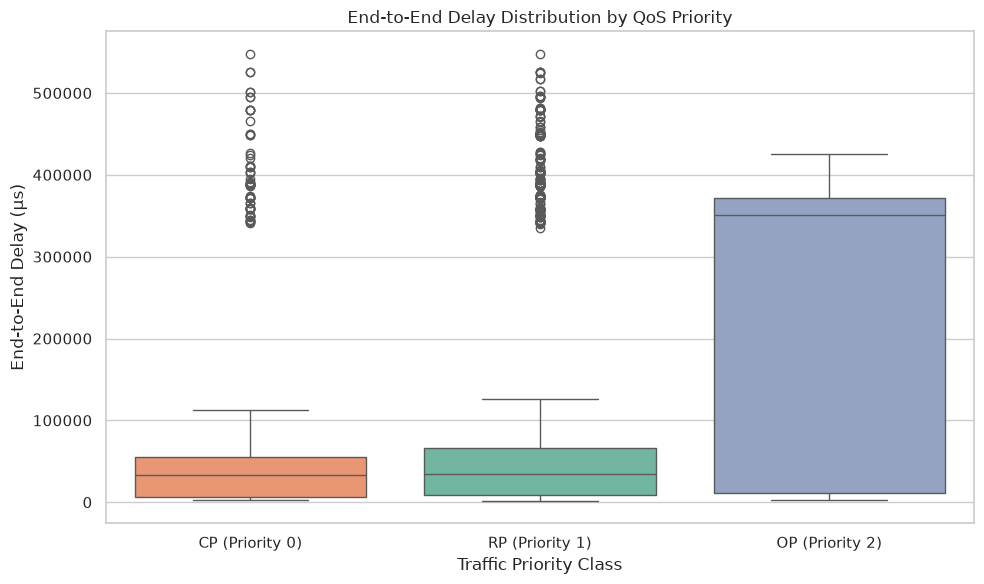

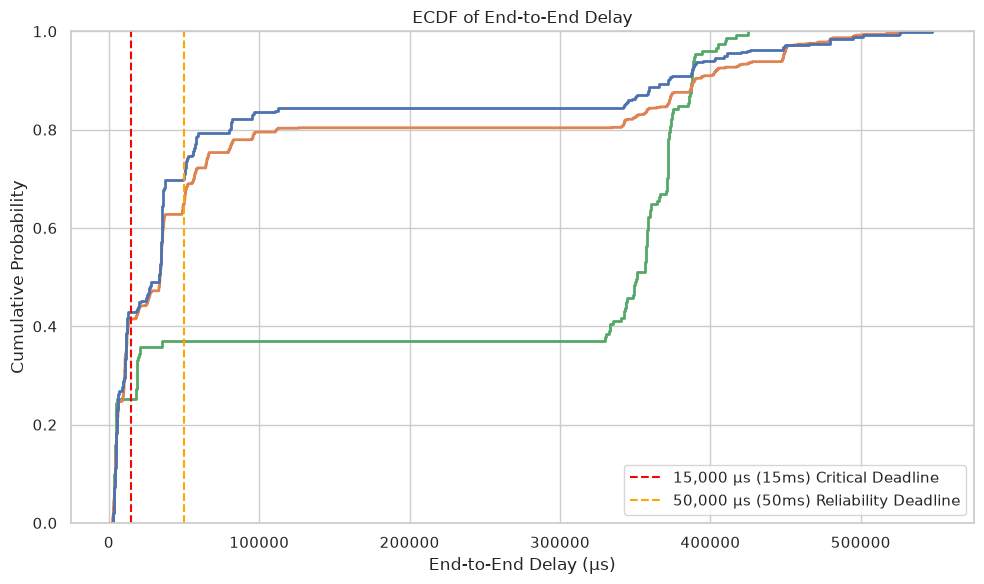

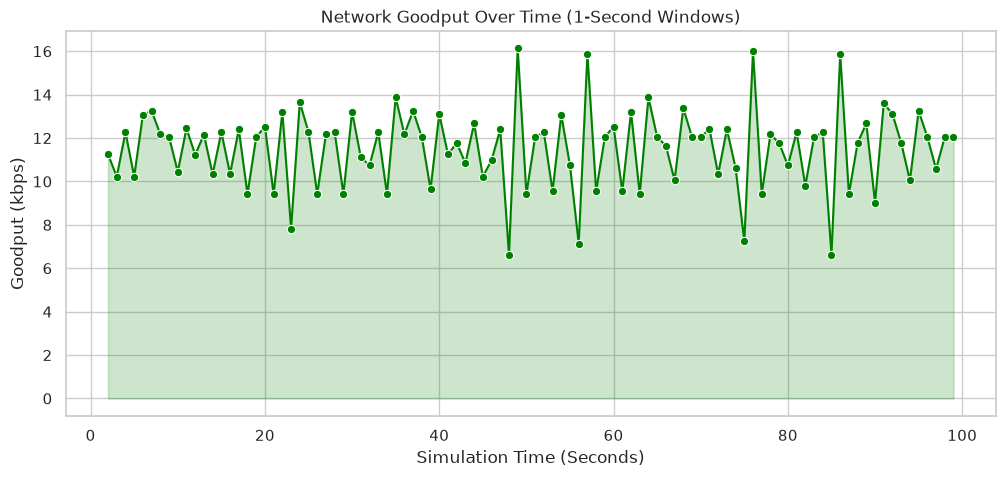

No packet drops recorded.


In [7]:
# =============================================================================
# 4. GLOBAL VISUALIZATIONS & DROP ANALYSIS
# =============================================================================
if not df_rx.empty:
    # A. End-to-End Delay Boxplot
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df_rx, x='QoS_Tag', y='E2EDelay_us', 
        hue='QoS_Tag', order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], 
        palette='Set2', legend=False
    )
    plt.title('End-to-End Delay Distribution by QoS Priority')
    plt.xlabel('Traffic Priority Class')
    plt.ylabel('End-to-End Delay (μs)')
    plt.tight_layout()
    plt.show()

    # B. ECDF Tail Latency (Fixed to μs deadlines)
    plt.figure(figsize=(10, 6))
    sns.ecdfplot(
        data=df_rx, x='E2EDelay_us', hue='QoS_Tag', 
        hue_order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], linewidth=2
    )
    plt.axvline(x=15_000, color='red', linestyle='--', label='15,000 μs (15ms) Critical Deadline')
    plt.axvline(x=50_000, color='orange', linestyle='--', label='50,000 μs (50ms) Reliability Deadline')
    plt.title('ECDF of End-to-End Delay')
    plt.xlabel('End-to-End Delay (μs)')
    plt.ylabel('Cumulative Probability')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # C. Rolling Network Goodput
    df_rx['Time_Window'] = df_rx['Time_s'].astype(int)
    rolling_goodput = df_rx.groupby('Time_Window')['Size_bytes'].sum() * 8 / 1000 # kbps
    if not rolling_goodput.empty:
        plt.figure(figsize=(12, 5))
        sns.lineplot(x=rolling_goodput.index, y=rolling_goodput.values, color='green', marker='o')
        plt.title('Network Goodput Over Time (1-Second Windows)')
        plt.xlabel('Simulation Time (Seconds)')
        plt.ylabel('Goodput (kbps)')
        plt.fill_between(rolling_goodput.index, rolling_goodput.values, alpha=0.2, color='green')
        plt.show()

if not df_drops.empty:
    print("--- DROP ANALYSIS ---")
    plt.figure(figsize=(12, 5))
    sns.histplot(data=df_drops, x='Time_s', hue='Layer', multiple='stack', bins=50, palette='magma')
    plt.title('Packet Drop Density Over Time by Network Layer')
    plt.xlabel('Simulation Time (Seconds)')
    plt.ylabel('Drop Count')
    plt.show()
    
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_drops, x='Layer', hue='QoS_Tag', hue_order=['CP (Priority 0)', 'RP (Priority 1)', 'OP (Priority 2)'], palette='Reds_d')
    plt.title('Packet Drops by Network Layer and QoS Priority')
    plt.xlabel('Drop Layer (APP = Buffer Drop-Tail, MAC = Channel Contention)')
    plt.ylabel('Drop Count')
    plt.legend(title='Priority')
    plt.show()
    
    drop_summary = df_drops.groupby(['NodeID', 'Layer', 'QoS_Tag']).size().reset_index(name='Drop_Count')
    display(drop_summary)
else:
    print("No packet drops recorded.")

--- PER-NODE STAGE TRACKING & PERFORMANCE ---


,NodeID,SensorName,SensorType,Total_Generated,Tx_Sensor,Rx_Coordinator,Rx_LPU,App_Drops,Mac_Drops,Overall_PDR_%,E2EDelay_us,Jitter_us
0,0,Unknown,Unknown,0.0,0.0,10,0.0,0,0,NaN,NaN,NaN
1,2,EEG,Streaming (P0),400.0,400.0,400,400.0,0,0,100.0,38641.40,41252.06
2,3,Respiration,Streaming (P0),200.0,200.0,200,200.0,0,0,100.0,53361.93,81526.44
3,4,Temperature,Routine (P2),19.0,19.0,19,19.0,0,0,100.0,276815.62,148973.58
4,5,ECG,Streaming (P0),400.0,400.0,400,400.0,0,0,100.0,60618.84,56158.88
5,6,BloodPressure,High Event (P1),9.0,9.0,9,9.0,0,0,100.0,30746.76,27091.94
6,7,InsulinPump,High Event (P1),6.0,6.0,6,6.0,0,0,100.0,88608.27,144865.66
7,8,SpO2,High Event (P1),98.0,98.0,98,98.0,0,0,100.0,167069.32,262801.13
8,9,Accelerometer,Routine (P2),200.0,200.0,199,199.0,0,0,99.5,205585.63,231745.33
9,10,EMG,Streaming (P0),200.0,200.0,200,200.0,0,0,100.0,132725.15,205071.93



--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---


,SensorType,Total_Generated,Tx_Sensor,Rx_Coordinator,Rx_LPU,App_Drops,Mac_Drops,E2EDelay_us,Jitter_us,Overall_PDR_%
0,High Event (P1),113.0,113.0,113,113.0,0,0,95474.78,144919.58,100.00
1,Routine (P2),418.0,418.0,417,417.0,0,0,240862.18,199393.57,99.76
2,Streaming (P0),1200.0,1200.0,1200,1200.0,0,0,71336.83,96002.33,100.00
3,Unknown,0.0,0.0,10,0.0,0,0,NaN,NaN,NaN


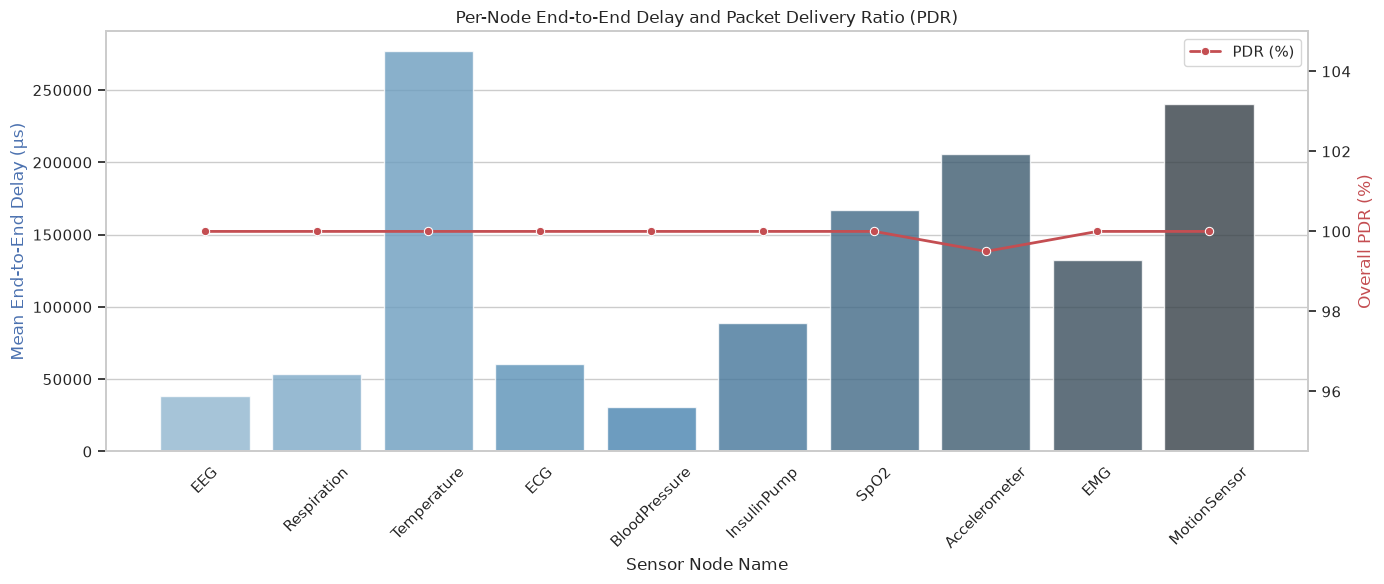

In [8]:
# =============================================================================
# 5. PER-NODE PERFORMANCE AGGREGATION & VISUALIZATION
# =============================================================================
if not df_tx.empty:
    tx_node = df_tx.groupby('NodeID').size().reset_index(name='Tx_Sensor')
    hub_node = hub_rx_df.groupby('NodeID').size().reset_index(name='Rx_Coordinator') if not hub_rx_df.empty else pd.DataFrame(columns=['NodeID', 'Rx_Coordinator'])
    lpu_node = df_rx.groupby('NodeID').size().reset_index(name='Rx_LPU') if not df_rx.empty else pd.DataFrame(columns=['NodeID', 'Rx_LPU'])
    
    node_perf = pd.merge(tx_node, hub_node, on='NodeID', how='outer')
    node_perf = pd.merge(node_perf, lpu_node, on='NodeID', how='outer').fillna(0)

    if not df_drops.empty:
        app_drops_node = df_drops[df_drops['Layer'] == 'APP'].groupby('NodeID').size().reset_index(name='App_Drops')
        mac_drops_node = df_drops[df_drops['Layer'] == 'MAC'].groupby('NodeID').size().reset_index(name='Mac_Drops')
        node_perf = pd.merge(node_perf, app_drops_node, on='NodeID', how='left')
        node_perf = pd.merge(node_perf, mac_drops_node, on='NodeID', how='left').fillna(0)
    else:
        node_perf['App_Drops'], node_perf['Mac_Drops'] = 0, 0

    node_perf['Total_Generated'] = node_perf['Tx_Sensor'] + node_perf['App_Drops']
    node_perf['Overall_PDR_%'] = (node_perf['Rx_LPU'] / node_perf['Total_Generated']) * 100

    if not df_rx.empty:
        mean_metrics = df_rx.groupby('NodeID')[['E2EDelay_us', 'Jitter_us']].mean().reset_index()
        node_perf = pd.merge(node_perf, mean_metrics, on='NodeID', how='left')
    else:
        node_perf['E2EDelay_us'], node_perf['Jitter_us'] = np.nan, np.nan

    node_perf['SensorName'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorName', 'Unknown'))
    node_perf['SensorType'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorType', 'Unknown'))

    cols = ['NodeID', 'SensorName', 'SensorType', 'Total_Generated', 'Tx_Sensor', 'Rx_Coordinator', 'Rx_LPU', 
            'App_Drops', 'Mac_Drops', 'Overall_PDR_%', 'E2EDelay_us', 'Jitter_us']
    node_perf = node_perf[cols].sort_values(by='NodeID').reset_index(drop=True)

    print("--- PER-NODE STAGE TRACKING & PERFORMANCE ---")
    display(node_perf.round(2))

    type_perf = node_perf.groupby('SensorType').agg({
        'Total_Generated': 'sum',
        'Tx_Sensor': 'sum',
        'Rx_Coordinator': 'sum',
        'Rx_LPU': 'sum',
        'App_Drops': 'sum',
        'Mac_Drops': 'sum',
        'E2EDelay_us': 'mean',
        'Jitter_us': 'mean'
    }).reset_index()
    
    type_perf['Overall_PDR_%'] = (type_perf['Rx_LPU'] / type_perf['Total_Generated']) * 100
    
    print("\n--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---")
    display(type_perf.round(2))

    # Visualization
    if not node_perf['E2EDelay_us'].isna().all():
        fig, ax1 = plt.subplots(figsize=(14, 6))

        # Fixed Deprecation Warning by mapping hue to x and turning legend off
        sns.barplot(data=node_perf, x='SensorName', y='E2EDelay_us', ax=ax1, palette='Blues_d', alpha=0.8, hue='SensorName', legend=False)
        ax1.set_title('Per-Node End-to-End Delay and Packet Delivery Ratio (PDR)')
        ax1.set_xlabel('Sensor Node Name')
        ax1.set_ylabel('Mean End-to-End Delay (μs)', color='b')
        ax1.tick_params(axis='x', rotation=45)

        ax2 = ax1.twinx()
        sns.lineplot(data=node_perf, x='SensorName', y='Overall_PDR_%', ax=ax2, color='r', marker='o', linewidth=2, label='PDR (%)')
        ax2.set_ylabel('Overall PDR (%)', color='r')

        min_pdr = node_perf['Overall_PDR_%'].min()
        ax2.set_ylim(max(0, min_pdr - 5), 105) 
        ax2.grid(False)

        plt.tight_layout()
        plt.show()